# License Plate Detection and Recognition

**Team 5: Pufa** <br> Hemo, Mohammad Javad, Sara, Mahdi <br> Sep 24, 2026

## Phase 0: Setup & Environment

In [27]:
# Cell 1: Install packages and setup environment
# !pip install -q ultralytics matplotlib opencv-python pyyaml gdown pandas

import os
import glob
import time
import shutil
import json
import random
import yaml
from PIL import Image
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from ultralytics import YOLO

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active device: {device}")

Active device: cuda


## Phase 1: License Plate Detection (YOLO)

#### 0. Directory Split

In [3]:
base_dir = os.getcwd()
images_dir = os.path.join(base_dir, 'images')
labels_dir = os.path.join(base_dir, 'labels')

train_images = os.path.join(images_dir, 'train')
val_images = os.path.join(images_dir, 'val')
train_labels = os.path.join(labels_dir, 'train')
val_labels = os.path.join(labels_dir, 'val')

for d in [train_images, val_images, train_labels, val_labels]:
    os.makedirs(d, exist_ok=True)

all_images = [f for f in os.listdir(images_dir) if os.path.isfile(os.path.join(images_dir, f))]

random.seed(42)
random.shuffle(all_images)
split_idx = int(0.8 * len(all_images))

train_files = all_images[:split_idx]
val_files = all_images[split_idx:]

def move_dataset_files(file_list, split_type):
    img_dest = train_images if split_type == 'train' else val_images
    lbl_dest = train_labels if split_type == 'train' else val_labels

    for file in file_list:
        src_img = os.path.join(images_dir, file)
        shutil.move(src_img, os.path.join(img_dest, file))
        
        filename_no_ext = os.path.splitext(file)[0]
        label_file = filename_no_ext + '.txt'
        src_lbl = os.path.join(labels_dir, label_file)
        
        if os.path.exists(src_lbl):
            shutil.move(src_lbl, os.path.join(lbl_dest, label_file))

move_dataset_files(train_files, 'train')
move_dataset_files(val_files, 'val')

print(f"Dataset successfully split: {len(train_files)} files in 'train', {len(val_files)} files in 'val'.")

Dataset successfully split: 0 files in 'train', 0 files in 'val'.


#### 1. Configure Dataset and `data.yaml`

In [4]:
yaml_content = {
    'path': os.getcwd(),
    'train': 'images/train',
    'val': 'images/val',
    'nc': 1,
    'names': {0: 'license_plate'}
}

yaml_path = os.path.join(os.getcwd(), "data.yaml")
with open(yaml_path, "w") as f:
    yaml.dump(yaml_content, f, default_flow_style=False)

print("Updated data.yaml:")

Updated data.yaml:


#### 2. Train and Validate YOLO

In [5]:
yolo_model = YOLO("yolov8n.pt")

# Kaggle will save automatically to /kaggle/working/runs/detect/lpd_yolo
yolo_results = yolo_model.train(
    data=yaml_path,
    epochs=25,
    imgsz=640,
    batch=45,      # Increased from 8 to fully utilize your 6GB VRAM
    workers=3,     # MUST stay 0 to prevent your system RAM from crashing again
    device=0,      
    name="lpd_yolo",
    save=True,
    plots=True
)

# After YOLO training completes
best_lpd_path = "./runs/detect/lpd_yolo/weights/best.pt"
best_lpd_model = YOLO(best_lpd_path)
print(f"Best YOLO weights saved at: {best_lpd_path}")

Ultralytics 8.4.159  Python-3.13.12 torch-2.10.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=45, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\Mahdi\Desktop\ML Bootcamp\Project 02 - License_Plate_Detection_&_Recognition\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, mo

## Phase 2: License Plate Recognition (PyTorch CNN)

#### 1. LPR Dataset and DataLoader

In [2]:
# 1. Locate all images and map filenames to their full paths
lpr_dir = os.getcwd()
all_image_paths = glob.glob(os.path.join(lpr_dir, "**", "*.jpg"), recursive=True) + \
                  glob.glob(os.path.join(lpr_dir, "**", "*.png"), recursive=True)

filename_to_path = {os.path.basename(p): p for p in all_image_paths}

# 2. Read the CSV and build valid_samples list
csv_path = os.path.join(lpr_dir, "valid_samples.csv")
df = pd.read_csv(csv_path)

valid_samples = []
for index, row in df.iterrows():
    img_filename = str(row['image_path'])
    label_str = str(row['label']).strip()
    
    # Ensure it's exactly 8 characters and the file actually exists
    if len(label_str) == 8 and img_filename in filename_to_path:
        full_path = filename_to_path[img_filename]
        valid_samples.append((full_path, label_str))

print(f"Successfully matched {len(valid_samples)} labeled images.")

# 3. Build the vocabulary mapping
all_chars = sorted(list({c for _, label in valid_samples for c in label}))
char2idx = {c: i for i, c in enumerate(all_chars)}
idx2char = {i: c for i, c in enumerate(all_chars)}
num_classes = len(char2idx)
print(f"Vocabulary ({num_classes} distinct classes): {char2idx}")

# 4. PyTorch Dataset Definition
class PLPRDataset(Dataset):
    def __init__(self, samples, char2idx, transform=None):
        self.samples = samples
        self.char2idx = char2idx
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label_str = self.samples[idx]
        image = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        
        target = torch.tensor([self.char2idx[c] for c in label_str], dtype=torch.long)
        return image, target

# 5. Transforms and Normalization
lpr_transform_train = transforms.Compose([
    transforms.Resize((64, 224)),
    transforms.RandomRotation(degrees=3),
    transforms.RandomPerspective(distortion_scale=0.2, p=0.5), # Added perspective warping
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

lpr_transform_val = transforms.Compose([
    transforms.Resize((64, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 6. Train/Val/Test Split & DataLoaders
total = len(valid_samples)
train_len = int(0.8 * total)
val_len = int(0.1 * total)
test_len = total - train_len - val_len

train_samples, val_samples, test_samples = torch.utils.data.random_split(
    valid_samples, [train_len, val_len, test_len], generator=torch.Generator().manual_seed(42)
)

train_dataset = PLPRDataset(train_samples, char2idx, transform=lpr_transform_train)
val_dataset = PLPRDataset(val_samples, char2idx, transform=lpr_transform_val)
test_dataset = PLPRDataset(test_samples, char2idx, transform=lpr_transform_val)

train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False, num_workers=0)

print(f"DataLoaders ready: {len(train_dataset)} Train | {len(val_dataset)} Val | {len(test_dataset)} Test")

Successfully matched 23519 labeled images.
Vocabulary (31 distinct classes): {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, 'آ': 10, 'ب': 11, 'ت': 12, 'ث': 13, 'ج': 14, 'د': 15, 'ز': 16, 'س': 17, 'ش': 18, 'ص': 19, 'ط': 20, 'ع': 21, 'ق': 22, 'ل': 23, 'م': 24, 'ن': 25, 'ه': 26, 'و': 27, 'پ': 28, 'ژ': 29, 'ی': 30}
DataLoaders ready: 18815 Train | 2351 Val | 2353 Test


#### 2. Model 1: Custom Architecture from Scratch

In [3]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += residual 
        return F.relu(out)

class CustomPlateCNN(nn.Module):
    def __init__(self, num_classes, num_chars=8):
        super().__init__()
        self.num_chars = num_chars

        # Stage 1: 32 Channels
        self.conv_in = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.res1 = ResidualBlock(32)
        
        # Stage 2: 64 Channels
        self.downsample1 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.res2 = ResidualBlock(64)
        
        # FIX 1: Stage 3 -> 128 Channels for deeper feature extraction
        self.downsample2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )
        self.res3 = ResidualBlock(128)
        
        # FIX 3: Increased Dropout to combat late-stage overfitting
        self.dropout = nn.Dropout(0.5)
        
        # Maintain spatial awareness (4 height x 8 width)
        self.pool = nn.AdaptiveAvgPool2d((4, 8))
        
        # 128 channels * 4 height * 8 width = 4096 features
        self.layer_norm = nn.LayerNorm(4096)

        # The heads now map from 4096 features instead of 2048
        self.heads = nn.ModuleList([
            nn.Linear(4096, num_classes) for _ in range(num_chars)
        ])

    def forward(self, x):
        x = self.conv_in(x)
        x = self.res1(x)
        
        x = self.downsample1(x)
        x = self.res2(x)
        
        # New third stage
        x = self.downsample2(x)
        x = self.res3(x)
        
        x = self.dropout(x)
        
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.layer_norm(x)

        return [head(x) for head in self.heads]

# Re-initialize the model to apply the new architecture
custom_cnn = CustomPlateCNN(num_classes=num_classes).to(device)

# Print the new parameter count
param_count = sum(p.numel() for p in custom_cnn.parameters() if p.requires_grad)
print(f"✅ Scaled Custom CNN Parameter Count: {param_count:,}")

✅ Scaled Custom CNN Parameter Count: 1,505,688


#### 3. Model 2: Fine-Tuned Pre-trained Backbone (MobileNetV2)

In [10]:
class PretrainedMobileNetLPR(nn.Module):
    def __init__(self, num_classes, num_chars=8):
        super().__init__()
        self.num_chars = num_chars
        backbone = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
        self.features = backbone.features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        in_features = backbone.last_channel 
        
        self.dropout = nn.Dropout(0.2)
        self.heads = nn.ModuleList([
            nn.Linear(in_features, num_classes) for _ in range(num_chars)
        ])

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return [head(x) for head in self.heads]

pretrained_lpr = PretrainedMobileNetLPR(num_classes=num_classes).to(device)

#### 4. Training, Stability, and Gradient Monitoring Engine

In [4]:
def train_evaluate_lpr(model, train_loader, val_loader, epochs=15, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)

    history = {
        'train_loss': [], 'val_loss': [],
        'val_char_acc': [], 'val_full_acc': [],
        'grad_norms': []
    }

    best_loss = float('inf')
    best_weights = None

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        total_grad_norm = 0.0
        batches = 0

        # Wrap the train_loader in tqdm for a live YOLO-style progress bar
        train_pbar = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{epochs}] Train", leave=False, unit="batch")
        
        for images, targets in train_pbar:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad()

            outputs = model(images)
            loss = sum(criterion(outputs[i], targets[:, i]) for i in range(8))
            loss.backward()

            grad_norm = 0.0
            for p in model.parameters():
                if p.grad is not None:
                    grad_norm += p.grad.data.norm(2).item() ** 2
            grad_norm = grad_norm ** 0.5
            total_grad_norm += grad_norm

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

            optimizer.step()
            running_loss += loss.item()
            batches += 1
            
            # Live update the loss metric on the progress bar
            train_pbar.set_postfix(loss=f"{loss.item():.4f}")

        avg_train_loss = running_loss / batches
        avg_grad_norm = total_grad_norm / batches

        model.eval()
        val_loss = 0.0
        correct_chars = 0
        correct_full = 0
        total_plates = 0

        # Wrap the val_loader for validation progress
        val_pbar = tqdm(val_loader, desc=f"Epoch [{epoch+1}/{epochs}] Val", leave=False, unit="batch")

        with torch.no_grad():
            for images, targets in val_pbar:
                images, targets = images.to(device), targets.to(device)
                outputs = model(images)
                loss = sum(criterion(outputs[i], targets[:, i]) for i in range(8))
                val_loss += loss.item()

                preds = torch.stack([torch.argmax(outputs[i], dim=1) for i in range(8)], dim=1)
                
                correct_chars += (preds == targets).sum().item()
                correct_full += (preds == targets).all(dim=1).sum().item()
                total_plates += targets.size(0)

                val_pbar.set_postfix(loss=f"{loss.item():.4f}")

        avg_val_loss = val_loss / len(val_loader)
        char_acc = correct_chars / (total_plates * 8)
        full_acc = correct_full / total_plates

        scheduler.step(avg_val_loss)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_char_acc'].append(char_acc)
        history['val_full_acc'].append(full_acc)
        history['grad_norms'].append(avg_grad_norm)

        # Print the final summary for the completed epoch
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
              f"Char Acc: {char_acc*100:.2f}% | Full Plate Acc: {full_acc*100:.2f}% | Avg Grad Norm: {avg_grad_norm:.4f}")

        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_weights = model.state_dict().copy()

    model.load_state_dict(best_weights)
    return history

#### 5. Train Both Models

In [5]:
# Create a dedicated directory for PyTorch weights
os.makedirs('./weights', exist_ok=True)

print("--- Training Custom CNN (From Scratch) ---")
custom_history = train_evaluate_lpr(custom_cnn, train_loader, val_loader, epochs=20, lr=1e-3)

# Save the Custom CNN state dictionary directly to the weights folder[cite: 6]
torch.save(custom_cnn.state_dict(), './weights/custom_cnn_best.pth')
print("✅ Custom CNN weights saved to: /kaggle/working/weights/custom_cnn_best.pth")


# print("\n--- Training Pretrained MobileNetV2 (Fine-Tuning) ---")
# pretrained_history = train_evaluate_lpr(pretrained_lpr, train_loader, val_loader, epochs=20, lr=5e-4)

# # Save the MobileNet state dictionary directly to the weights folder[cite: 6]
# torch.save(pretrained_lpr.state_dict(), './weights/mobilenet_lpr_best.pth')
# print("✅ MobileNet weights saved to: /kaggle/working/weights/mobilenet_lpr_best.pth")

--- Training Custom CNN (From Scratch) ---


Epoch [1/20] | Train Loss: 18.1883 | Val Loss: 14.1316 | Char Acc: 34.34% | Full Plate Acc: 0.00% | Avg Grad Norm: 16.2868


Epoch [2/20] | Train Loss: 9.9699 | Val Loss: 6.9447 | Char Acc: 69.43% | Full Plate Acc: 10.97% | Avg Grad Norm: 15.0529


Epoch [3/20] | Train Loss: 3.8786 | Val Loss: 2.1046 | Char Acc: 92.20% | Full Plate Acc: 66.74% | Avg Grad Norm: 11.8214


Epoch [4/20] | Train Loss: 2.1742 | Val Loss: 1.5160 | Char Acc: 94.84% | Full Plate Acc: 77.41% | Avg Grad Norm: 8.1211


Epoch [5/20] | Train Loss: 1.6547 | Val Loss: 1.4833 | Char Acc: 94.83% | Full Plate Acc: 76.78% | Avg Grad Norm: 8.1505


... (11 outputs left out)

Epoch [17/20] | Train Loss: 0.4533 | Val Loss: 0.9452 | Char Acc: 97.53% | Full Plate Acc: 88.22% | Avg Grad Norm: 4.7139


Epoch [18/20] | Train Loss: 0.3983 | Val Loss: 1.0099 | Char Acc: 97.30% | Full Plate Acc: 86.69% | Avg Grad Norm: 4.3225


Epoch [19/20] | Train Loss: 0.3815 | Val Loss: 0.8946 | Char Acc: 97.63% | Full Plate Acc: 88.01% | Avg Grad Norm: 4.3920


Epoch [20/20] | Train Loss: 0.3026 | Val Loss: 0.8024 | Char Acc: 98.00% | Full Plate Acc: 90.51% | Avg Grad Norm: 3.2592
✅ Custom CNN weights saved to: /kaggle/working/weights/custom_cnn_best.pth


In [8]:
# Ensure the weights folder exists
os.makedirs('./weights', exist_ok=True)

# 1. Save Custom CNN History
with open('./weights/custom_history.json', 'w') as f:
    json.dump(custom_history, f, indent=4)
print("✅ Custom CNN training history saved to ./weights/custom_history.json")

# # 2. Save MobileNet History
# with open('./weights/mobilenet_history.json', 'w') as f:
#     json.dump(pretrained_history, f, indent=4)
# print("✅ MobileNet training history saved to ./weights/mobilenet_history.json")

✅ Custom CNN training history saved to ./weights/custom_history.json


## Phase 3: End-to-End Pipeline

Loading trained weights from disk...

[1/10] Testing Image: 001243.jpg
  🏎️ MobileNetV2 | Output: 43ص19922
     Latencies   | Preprocess: 732.80ms | Inference: 180.57ms | Postprocess: 48.06ms
  🧠 Custom CNN  | Output: 43ص19922
     Latencies   | Preprocess: 93.97ms | Inference: 9.61ms | Postprocess: 10.02ms

[2/10] Testing Image: 001133.jpg
  🏎️ MobileNetV2 | Output: 93ت38368
     Latencies   | Preprocess: 76.58ms | Inference: 9.67ms | Postprocess: 0.76ms
  🧠 Custom CNN  | Output: 93ت38368
     Latencies   | Preprocess: 39.41ms | Inference: 4.29ms | Postprocess: 1.08ms

[3/10] Testing Image: 000251.jpg
  🏎️ MobileNetV2 | Output: 19ب89536
     Latencies   | Preprocess: 76.31ms | Inference: 5.72ms | Postprocess: 125.34ms
  🧠 Custom CNN  | Output: 19ب89536
     Latencies   | Preprocess: 51.81ms | Inference: 3.14ms | Postprocess: 4.23ms

[4/10] Testing Image: 005398.jpg
  🏎️ MobileNetV2 | Output: 42و22844
     Latencies   | Preprocess: 54.81ms | Inference: 5.60ms | Postprocess: 0.43ms
  🧠 

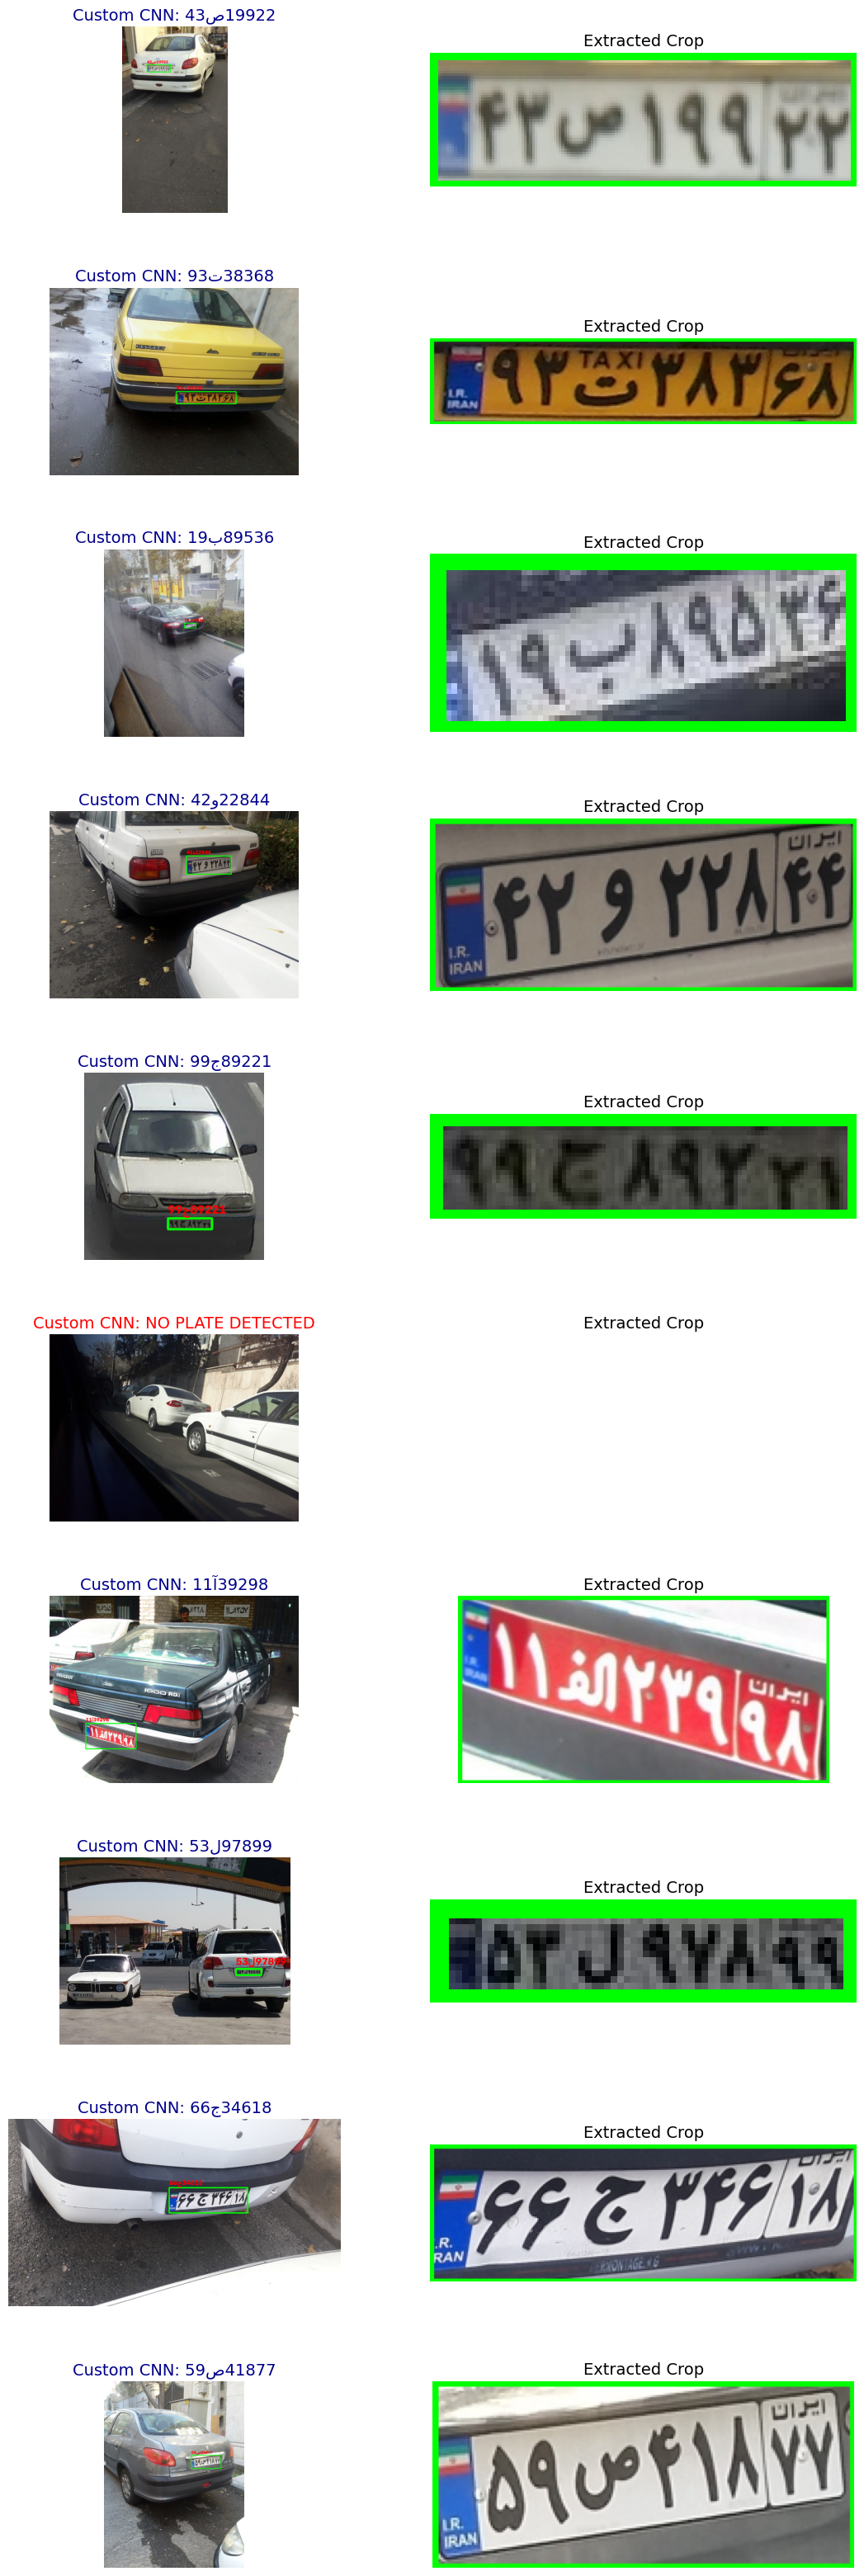

In [11]:
class EndToEndLPDR:
    def __init__(self, lpd_model, lpr_model, idx2char, device):
        self.lpd_model = lpd_model
        self.lpr_model = lpr_model.eval().to(device)
        self.idx2char = idx2char
        self.device = device
        self.transform = transforms.Compose([
            transforms.Resize((64, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def predict_image(self, img_input, conf_thresh=0.4):
        # --- Preprocessing (Image Load, YOLO Detect, Tensor Crop) ---
        t0 = time.time()
        if isinstance(img_input, str):
            orig_bgr = cv2.imread(img_input)
        else:
            orig_bgr = img_input.copy()

        orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
        h, w, _ = orig_rgb.shape

        # YOLO Detection
        yolo_out = self.lpd_model(orig_rgb, conf=conf_thresh, verbose=False)[0]

        predictions = []
        timings = {"preprocess": 0.0, "inference": 0.0, "postprocess": 0.0}
        
        if len(yolo_out.boxes) == 0:
            return orig_rgb, predictions, timings, None

        # Grab the highest confidence plate (first box)
        box = yolo_out.boxes[0]
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)

        crop = orig_rgb[y1:y2, x1:x2]
        if crop.size == 0 or (x2 - x1) < 10 or (y2 - y1) < 10:
            return orig_rgb, predictions, timings, None

        pil_crop = Image.fromarray(crop)
        tensor_crop = self.transform(pil_crop).unsqueeze(0).to(self.device)
        
        t1 = time.time()
        timings["preprocess"] = (t1 - t0) * 1000

        # --- Inference (LPR Model Forward Pass) ---
        with torch.no_grad():
            heads_out = self.lpr_model(tensor_crop)
            
        t2 = time.time()
        timings["inference"] = (t2 - t1) * 1000

        # --- Postprocessing (Argmax, Decoding, Bounding Box Drawing) ---
        predicted_chars = [self.idx2char[torch.argmax(head, dim=1).item()] for head in heads_out]
        plate_str = "".join(predicted_chars)

        predictions.append({'box': (x1, y1, x2, y2), 'text': plate_str})

        cv2.rectangle(orig_rgb, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(orig_rgb, plate_str, (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)
        
        t3 = time.time()
        timings["postprocess"] = (t3 - t2) * 1000

        return orig_rgb, predictions, timings, crop


# 1. Load Weights from Disk
print("Loading trained weights from disk...")
best_lpd_model = YOLO("./runs/detect/lpd_yolo/weights/best.pt")

custom_cnn.load_state_dict(torch.load('./weights/custom_cnn_best.pth'))
pretrained_lpr.load_state_dict(torch.load('./weights/mobilenet_lpr_best.pth'))

# 2. Instantiate Pipelines
pipeline_cnn = EndToEndLPDR(best_lpd_model, custom_cnn, idx2char, device)
pipeline_mob = EndToEndLPDR(best_lpd_model, pretrained_lpr, idx2char, device)

# 3. Grab 10 Random Images
all_images = glob.glob(os.path.join(os.getcwd(), 'images', "**", "*.jpg"), recursive=True)
random.seed(42)
test_image_paths = random.sample(all_images, 10)

# 4. Set up Plot for Custom CNN
fig, axes = plt.subplots(10, 2, figsize=(14, 40))
plt.subplots_adjust(hspace=0.4, wspace=0.1)

for i, path in enumerate(test_image_paths):
    print(f"\n[{i+1}/10] Testing Image: {os.path.basename(path)}")
    
    # --- MobileNet Evaluation (Text Only) ---
    _, preds_mob, times_mob, _ = pipeline_mob.predict_image(path)
    mob_text = preds_mob[0]['text'] if preds_mob else "NO PLATE DETECTED"
    print(f"  🏎️ MobileNetV2 | Output: {mob_text}")
    print(f"     Latencies   | Preprocess: {times_mob['preprocess']:.2f}ms | Inference: {times_mob['inference']:.2f}ms | Postprocess: {times_mob['postprocess']:.2f}ms")
    
    # --- Custom CNN Evaluation (Text + Plotting) ---
    annotated_img, preds_cnn, times_cnn, crop_img = pipeline_cnn.predict_image(path)
    cnn_text = preds_cnn[0]['text'] if preds_cnn else "NO PLATE DETECTED"
    print(f"  🧠 Custom CNN  | Output: {cnn_text}")
    print(f"     Latencies   | Preprocess: {times_cnn['preprocess']:.2f}ms | Inference: {times_cnn['inference']:.2f}ms | Postprocess: {times_cnn['postprocess']:.2f}ms")
    
    # Plot Annotated Original
    axes[i, 0].imshow(annotated_img)
    axes[i, 0].axis("off")
    axes[i, 0].set_title(f"Custom CNN: {cnn_text}", fontsize=14, color='darkblue' if preds_cnn else 'red')
    
    # Plot Cropped Plate
    if crop_img is not None and crop_img.size > 0:
        axes[i, 1].imshow(crop_img)
    axes[i, 1].axis("off")
    axes[i, 1].set_title("Extracted Crop", fontsize=14)

plt.show()

## Phase 4: Some Analysis

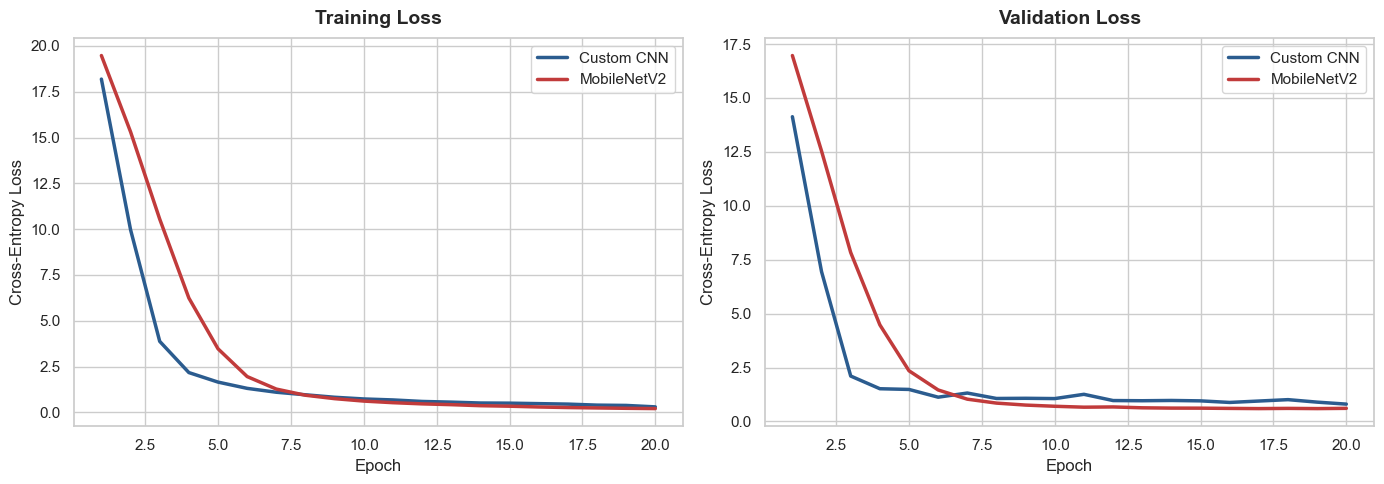

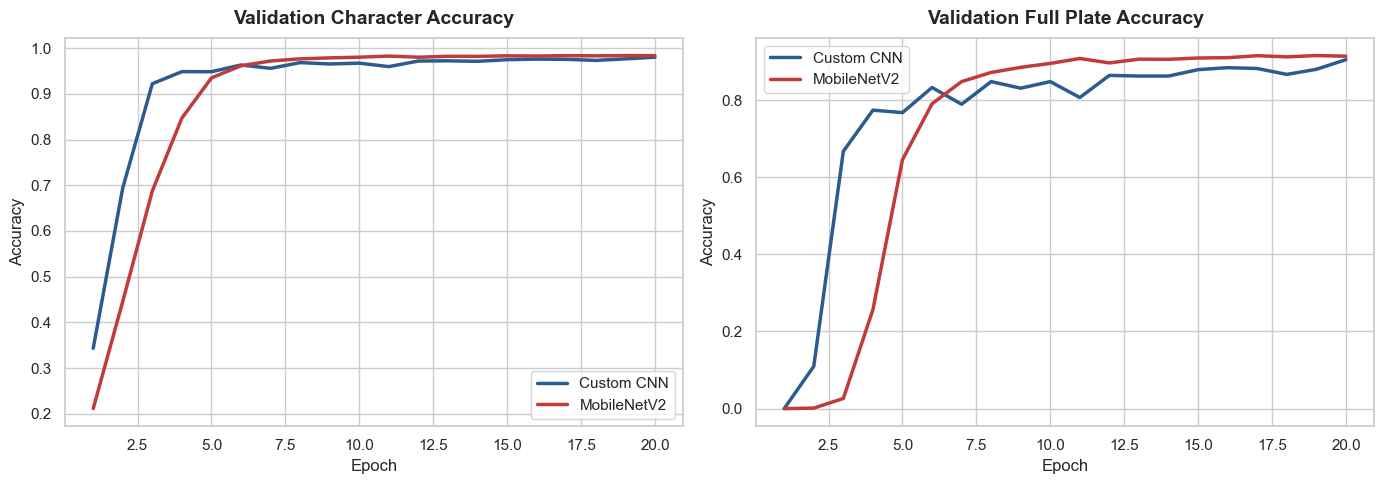

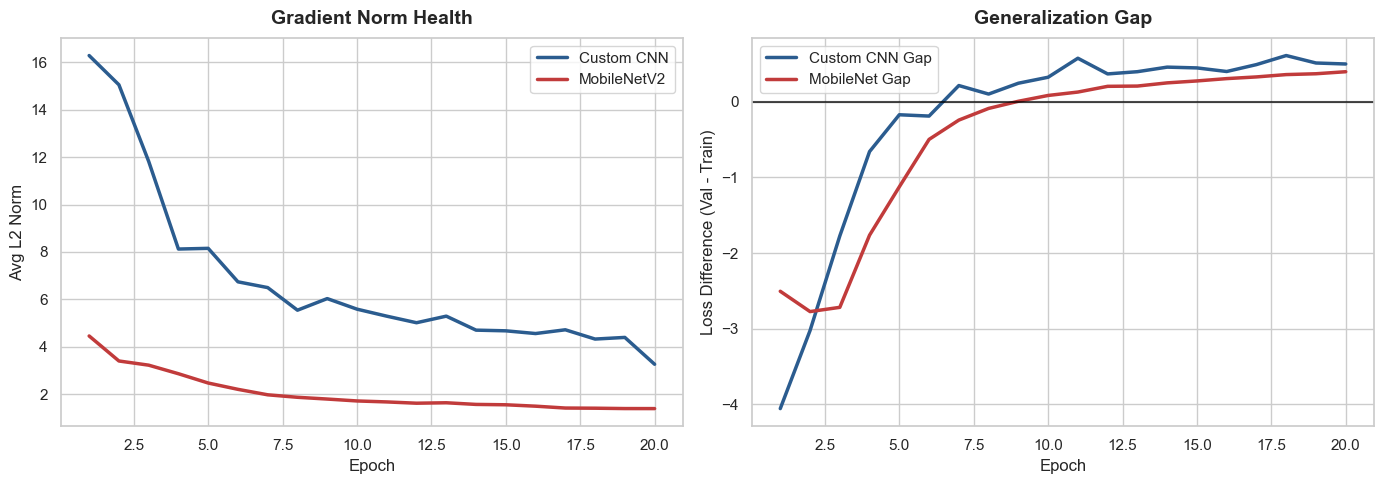

C:\Users\Mahdi\AppData\Local\Temp\ipykernel_8604\1693518294.py:98: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comparison, x="Model", y="Numeric Params", ax=axs4[1], palette=[c_custom, c_mob])


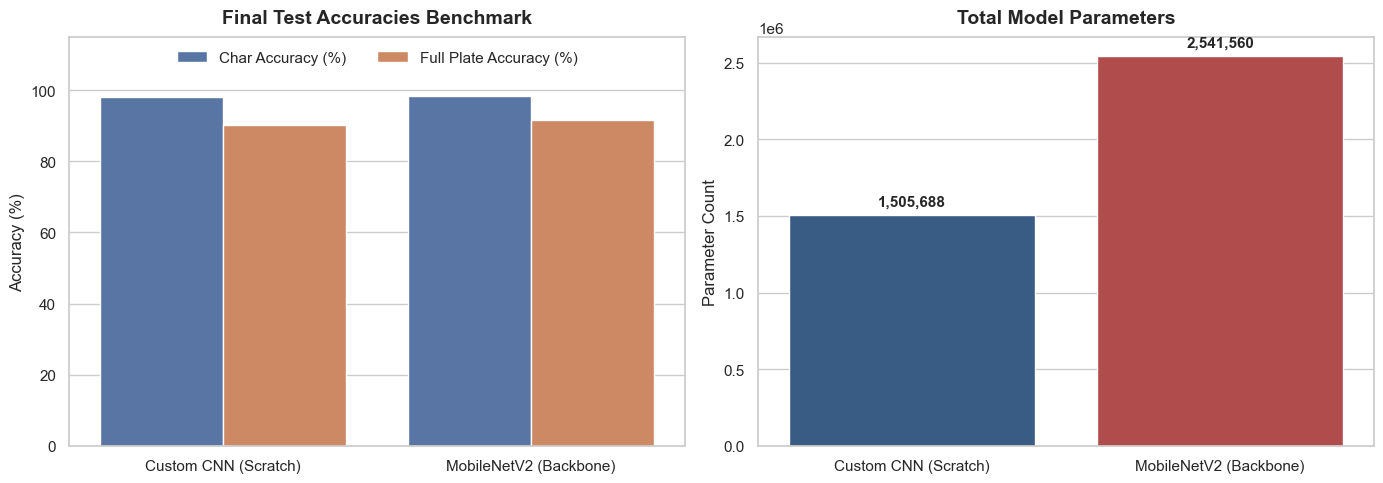

In [45]:
# 1. Apply Seaborn theme globally
sns.set_theme(style="whitegrid", palette="deep", context="notebook")
os.makedirs('./output_images', exist_ok=True)

# 2. Load the saved history dictionaries
with open('./weights/custom_history.json', 'r') as f:
    custom_history = json.load(f)

with open('./weights/mobilenet_history.json', 'r') as f:
    pretrained_history = json.load(f)

epochs_range = range(1, len(custom_history['train_loss']) + 1)

# Uniform colors
c_custom = "#2b5c8f"  # Deep blue
c_mob = "#c13b3b"     # Crimson

# Helper function to plot lines using Seaborn
def plot_metric(ax, metric_key, title, ylabel):
    sns.lineplot(x=epochs_range, y=custom_history[metric_key], label='Custom CNN', color=c_custom, linewidth=2.5, ax=ax)
    sns.lineplot(x=epochs_range, y=pretrained_history[metric_key], label='MobileNetV2', color=c_mob, linewidth=2.5, ax=ax)
    ax.set_title(title, fontsize=14, pad=10, fontweight='bold')
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)

# ==========================================
# FIGURE 1: Training & Validation Losses
# ==========================================
fig1, axs1 = plt.subplots(1, 2, figsize=(14, 5))

plot_metric(axs1[0], 'train_loss', "Training Loss", "Cross-Entropy Loss")
plot_metric(axs1[1], 'val_loss', "Validation Loss", "Cross-Entropy Loss")

plt.tight_layout()
plt.savefig('./output_images/phase2_losses_1x2.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# ==========================================
# FIGURE 2: Character & Full Plate Accuracy
# ==========================================
fig2, axs2 = plt.subplots(1, 2, figsize=(14, 5))

plot_metric(axs2[0], 'val_char_acc', "Validation Character Accuracy", "Accuracy")
plot_metric(axs2[1], 'val_full_acc', "Validation Full Plate Accuracy", "Accuracy")

plt.tight_layout()
plt.savefig('./output_images/phase2_accuracies_1x2.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# ==========================================
# FIGURE 3: Gradient Norms & Generalization
# ==========================================
fig3, axs3 = plt.subplots(1, 2, figsize=(14, 5))

plot_metric(axs3[0], 'grad_norms', "Gradient Norm Health", "Avg L2 Norm")

custom_gap = np.array(custom_history['val_loss']) - np.array(custom_history['train_loss'])
mobilenet_gap = np.array(pretrained_history['val_loss']) - np.array(pretrained_history['train_loss'])

sns.lineplot(x=epochs_range, y=custom_gap, label='Custom CNN Gap', color=c_custom, linewidth=2.5, ax=axs3[1])
sns.lineplot(x=epochs_range, y=mobilenet_gap, label='MobileNet Gap', color=c_mob, linewidth=2.5, ax=axs3[1])
axs3[1].axhline(0, color='black', linewidth=1.5, alpha=0.7) 
axs3[1].set_title("Generalization Gap", fontsize=14, pad=10, fontweight='bold')
axs3[1].set_xlabel("Epoch")
axs3[1].set_ylabel("Loss Difference (Val - Train)")
axs3[1].legend()

plt.tight_layout()
plt.savefig('./output_images/phase2_grad_gengap_1x2.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# ==========================================
# FIGURE 4: Final Benchmarks & Parameter Size
# ==========================================
fig4, axs4 = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Final Test Accuracies
df_melted = df_comparison.melt(
    id_vars="Model", 
    value_vars=["Char Accuracy (%)", "Full Plate Accuracy (%)"], 
    var_name="Metric", 
    value_name="Accuracy"
)
sns.barplot(data=df_melted, x="Model", y="Accuracy", hue="Metric", ax=axs4[0], palette=["#4c72b0", "#dd8452"])
axs4[0].set_title("Final Test Accuracies Benchmark", fontsize=14, pad=10, fontweight='bold')
axs4[0].set_ylim(0, 115) 
axs4[0].set_ylabel("Accuracy (%)")
axs4[0].set_xlabel("")
sns.move_legend(axs4[0], "upper center", bbox_to_anchor=(0.5, 1.0), ncol=2, title=None, frameon=False)

# Plot B: Parameter Sizes
# Strip commas from the "Parameters" string column and convert to integer for plotting
df_comparison['Numeric Params'] = df_comparison['Parameters'].astype(str).str.replace(',', '').astype(int)

sns.barplot(data=df_comparison, x="Model", y="Numeric Params", ax=axs4[1], palette=[c_custom, c_mob])
axs4[1].set_title("Total Model Parameters", fontsize=14, pad=10, fontweight='bold')
axs4[1].set_ylabel("Parameter Count")
axs4[1].set_xlabel("")

# Add numeric labels on top of the parameter bars
for i, p in enumerate(axs4[1].patches):
    height = p.get_height()
    axs4[1].annotate(f'{int(height):,}', 
                     (p.get_x() + p.get_width() / 2., height), 
                     ha='center', va='bottom', fontsize=11, fontweight='bold', 
                     xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.savefig('./output_images/phase2_benchmarks_1x2.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [13]:
# Define the benchmarking function
def evaluate_model_benchmark(model, test_loader, name="Model"):
    model.eval()
    total_plates = 0
    correct_full = 0
    correct_chars = 0
    
    # Measure inference latency
    start_time = time.time()
    with torch.no_grad():
        for images, targets in test_loader:
            images, targets = images.to(device), targets.to(device)
            outputs = model(images)
            preds = torch.stack([torch.argmax(outputs[i], dim=1) for i in range(8)], dim=1)
            correct_chars += (preds == targets).sum().item()
            correct_full += (preds == targets).all(dim=1).sum().item()
            total_plates += targets.size(0)
            
    total_time = time.time() - start_time
    avg_latency = (total_time / total_plates) * 1000 # in ms
    param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

    return {
        "Model": name,
        "Parameters": f"{param_count:,}",
        "Char Accuracy (%)": round((correct_chars / (total_plates * 8)) * 100, 2),
        "Full Plate Accuracy (%)": round((correct_full / total_plates) * 100, 2),
        "Latency (ms/plate)": round(avg_latency, 2)
    }

# Run the benchmark on both models
metrics_custom = evaluate_model_benchmark(custom_cnn, test_loader, "Custom CNN (Scratch)")
metrics_pretrained = evaluate_model_benchmark(pretrained_lpr, test_loader, "MobileNetV2 (Backbone)")

# Combine into the missing DataFrame
df_comparison = pd.DataFrame([metrics_custom, metrics_pretrained])
display(df_comparison)

,Model,Parameters,Char Accuracy (%),Full Plate Accuracy (%),Latency (ms/plate)
0,Custom CNN (Scratch),"1,505,688",98.05,90.35,2.79
1,MobileNetV2 (Backbone),"2,541,560",98.46,91.54,2.36


✅ Trade-off plot saved to ./output_images/accuracy_vs_latency_tradeoff.png


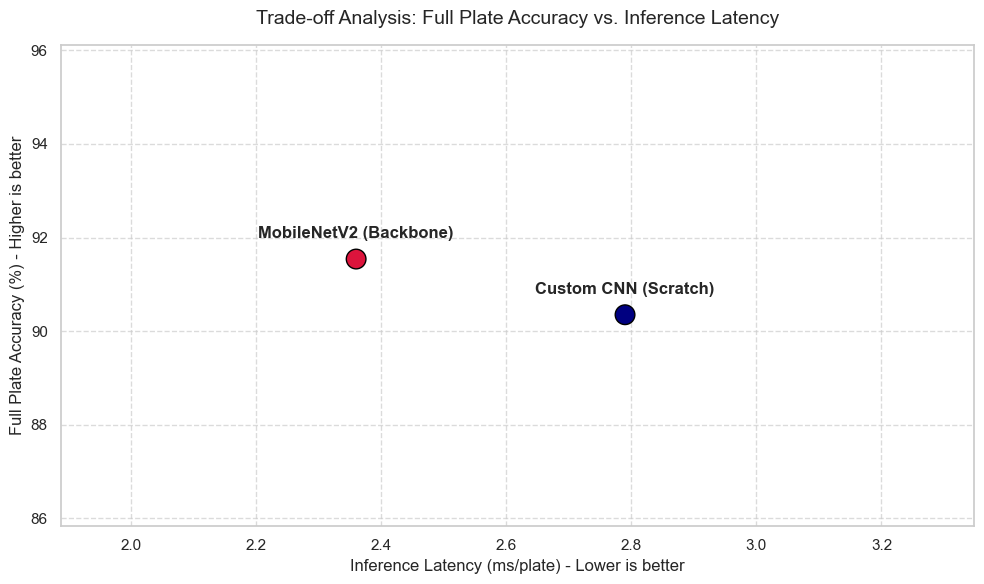

In [31]:
# Ensure the output directory exists for your final report
os.makedirs('./output_images', exist_ok=True)

# Extract data directly from the df_comparison DataFrame
models = df_comparison['Model']
latencies = df_comparison['Latency (ms/plate)']
accuracies = df_comparison['Full Plate Accuracy (%)']

plt.figure(figsize=(10, 6))

# Create the scatter plot with distinct colors
colors = ['navy', 'crimson']
plt.scatter(latencies, accuracies, c=colors[:len(models)], s=200, zorder=5, edgecolors='black')

# Annotate each point with its corresponding Model name
for i, model in enumerate(models):
    plt.annotate(model, (latencies[i], accuracies[i]), 
                 textcoords="offset points", 
                 xytext=(0, 15), 
                 ha='center', 
                 fontsize=12, 
                 fontweight='bold')

# Formatting the chart
plt.title('Trade-off Analysis: Full Plate Accuracy vs. Inference Latency', fontsize=14, pad=15)
plt.xlabel('Inference Latency (ms/plate) - Lower is better', fontsize=12)
plt.ylabel('Full Plate Accuracy (%) - Higher is better', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Dynamically pad the axes so the labels don't get cut off
plt.xlim(latencies.min() * 0.8, latencies.max() * 1.2)
plt.ylim(accuracies.min() * 0.95, accuracies.max() * 1.05)

plt.tight_layout()

# Save the high-resolution image for your report
save_path = './output_images/accuracy_vs_latency_tradeoff.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"✅ Trade-off plot saved to {save_path}")

plt.show()

Scanning dataset using source: TEST_SAMPLES (In-Memory)...
Found 3 recognition failures.
✅ Recognition failure grid saved to: output_images\recognition_failures_grid.png


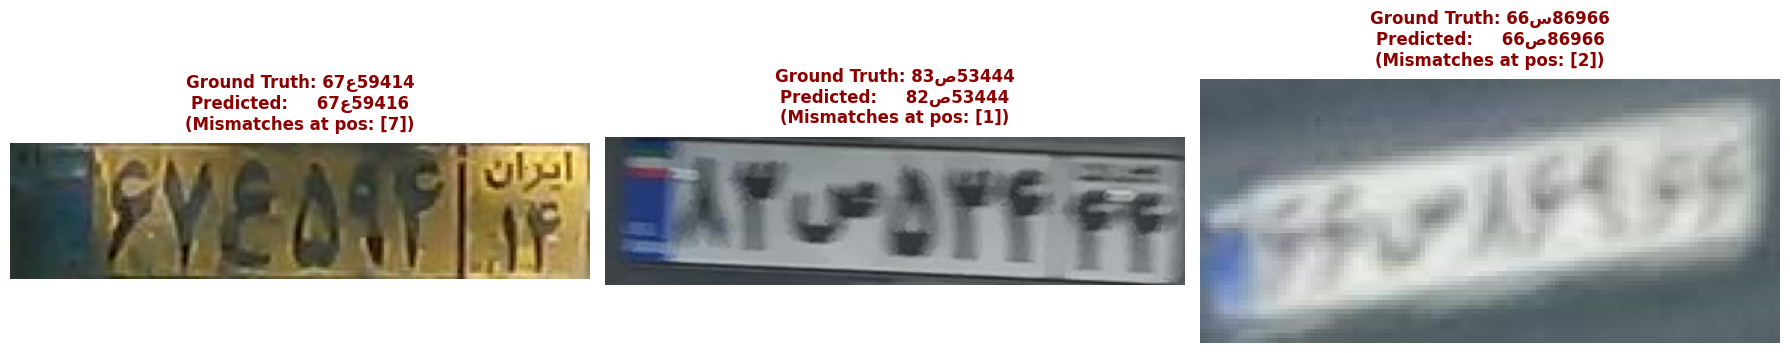

In [26]:
output_dir = "output_images"
os.makedirs(output_dir, exist_ok=True)

recognition_failures = []
print("Scanning dataset using source: TEST_SAMPLES (In-Memory)...")

# 1. Select active LPR model from memory
active_lpr = best_lpr_model if 'best_lpr_model' in globals() else (pretrained_lpr if 'pretrained_lpr' in globals() else custom_cnn)
active_lpr.eval()

# 2. Evaluate directly on the unseen Phase 2 test samples in memory
for img_path, true_plate in test_samples:
    if not os.path.exists(img_path):
        continue
        
    img_pil = Image.open(img_path).convert("RGB")
    tensor_crop = lpr_transform_val(img_pil).unsqueeze(0).to(device)
    
    with torch.no_grad():
        heads_out = active_lpr(tensor_crop)
        pred_chars = [idx2char[torch.argmax(head, dim=1).item()] for head in heads_out]
        pred_plate = "".join(pred_chars)
        
    if pred_plate != true_plate:
        recognition_failures.append({
            'image': np.array(img_pil),
            'true': true_plate,
            'pred': pred_plate,
            'path': img_path
        })
        
    if len(recognition_failures) >= 3:
        break

print(f"Found {len(recognition_failures)} recognition failures.")

# 3. Plot the Failure Grid
if recognition_failures:
    n_plots = min(3, len(recognition_failures))
    fig, axes = plt.subplots(1, n_plots, figsize=(6 * n_plots, 5))
    if n_plots == 1:
        axes = [axes]

    for i, fail in enumerate(recognition_failures[:n_plots]):
        axes[i].imshow(fail['image'])
        axes[i].axis("off")
        
        # Highlight position mismatches
        diffs = [idx for idx in range(min(len(fail['true']), len(fail['pred']))) if fail['true'][idx] != fail['pred'][idx]]
        diff_desc = f"Mismatches at pos: {diffs}" if diffs else "Length mismatch"
        
        axes[i].set_title(
            f"Ground Truth: {fail['true']}\n"
            f"Predicted:     {fail['pred']}\n"
            f"({diff_desc})",
            fontsize=12, fontweight='bold', color='darkred', pad=10
        )

    plt.tight_layout()
    save_path = os.path.join(output_dir, "recognition_failures_grid.png")
    plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✅ Recognition failure grid saved to: {save_path}")
    plt.show()
else:
    print("⚠️ No recognition failures found in the test_samples list.")

Top 10 Most Frequent Character Confusions:
41 times | True: 2 -> Predicted: 3
37 times | True: 3 -> Predicted: 2
16 times | True: 7 -> Predicted: 2
15 times | True: س -> Predicted: ص
10 times | True: 4 -> Predicted: 6
9 times | True: 1 -> Predicted: 9
8 times | True: 4 -> Predicted: 9
8 times | True: 2 -> Predicted: 7
8 times | True: 1 -> Predicted: 8
7 times | True: 8 -> Predicted: 5

✅ Confusion matrix saved to ./output_images/character_confusion_matrix.png


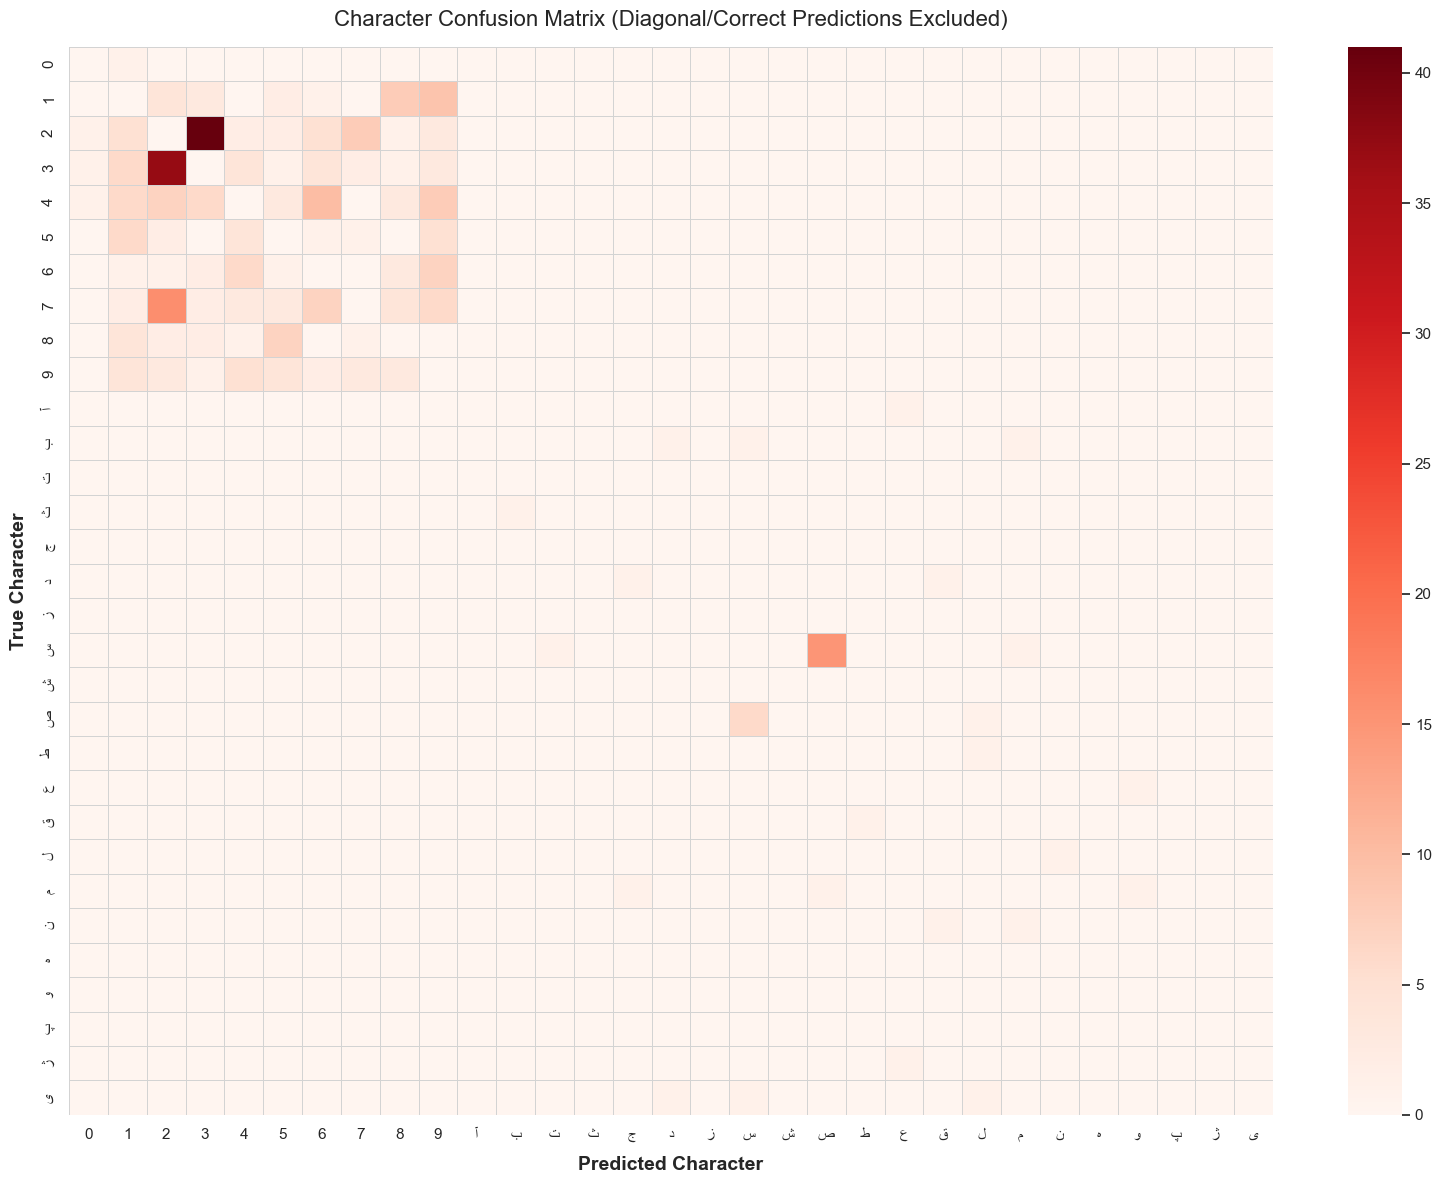

In [46]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
from collections import Counter

# 1. Flatten all predictions and targets from the test set
all_true = []
all_pred = []


best_lpr_model = custom_cnn
# Ensure we evaluate your best model (either Custom CNN or MobileNet)
best_lpr_model.eval()

with torch.no_grad():
    for images, targets in test_loader:
        images, targets = images.to(device), targets.to(device)
        
        # Forward pass
        outputs = best_lpr_model(images)
        
        # Stack the 8 classification heads and get the predicted indices
        preds = torch.stack([torch.argmax(outputs[i], dim=1) for i in range(8)], dim=1)
        
        # Flatten the batch to compare raw characters sequentially
        all_true.extend(targets.cpu().numpy().flatten())
        all_pred.extend(preds.cpu().numpy().flatten())

# 2. Map indices back to actual characters
true_chars = [idx2char[idx] for idx in all_true]
pred_chars = [idx2char[idx] for idx in all_pred]

# 3. Print the top 10 most frequent mistakes
confusions = [f"True: {t} -> Predicted: {p}" for t, p in zip(true_chars, pred_chars) if t != p]
top_confusions = Counter(confusions).most_common(10)

print("Top 10 Most Frequent Character Confusions:")
for conf, count in top_confusions:
    print(f"{count} times | {conf}")

# 4. Generate the Confusion Matrix Heatmap
labels = [idx2char[i] for i in range(len(idx2char))]
cm = confusion_matrix(all_true, all_pred, labels=range(len(idx2char)))

# Zero out the diagonal (correct predictions) so the heatmap scale highlights the errors
np.fill_diagonal(cm, 0)

plt.figure(figsize=(16, 12))
sns.heatmap(cm, xticklabels=labels, yticklabels=labels, cmap="Reds", 
            annot=False, fmt="d", linewidths=0.5, linecolor='lightgray')

plt.title("Character Confusion Matrix (Diagonal/Correct Predictions Excluded)", fontsize=16, pad=15)
plt.xlabel("Predicted Character", fontsize=14, fontweight='bold', labelpad=10)
plt.ylabel("True Character", fontsize=14, fontweight='bold', labelpad=10)

plt.tight_layout()

# Save for your Phase 4 Deliverables
os.makedirs('./output_images', exist_ok=True)
save_path = './output_images/character_confusion_matrix.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
print(f"\n✅ Confusion matrix saved to {save_path}")

plt.show()

Evaluating character-level performance on the test set...
✅ Worst-performing characters plot saved to: ./output_images/top5_worst_characters.png


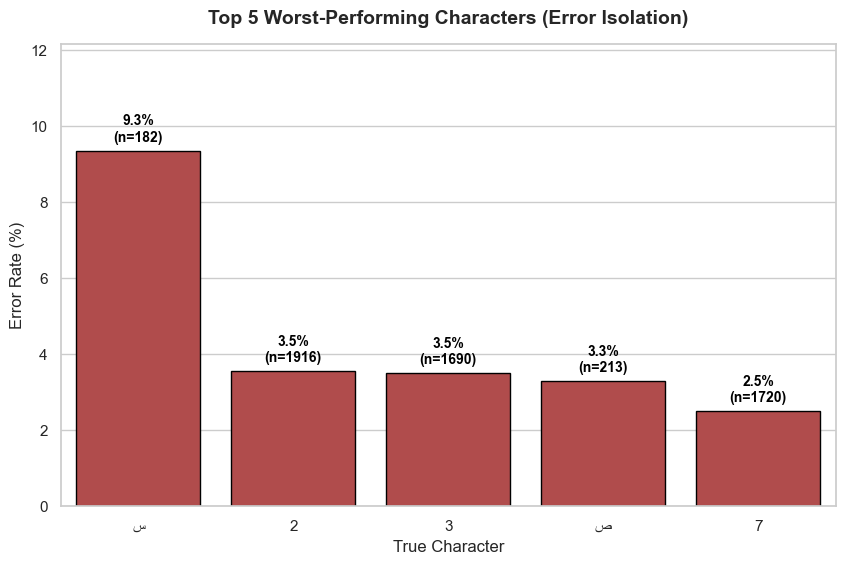

In [41]:
# 1. Select the active PyTorch model
active_lpr = best_lpr_model if 'best_lpr_model' in globals() else (pretrained_lpr if 'pretrained_lpr' in globals() else custom_cnn)
active_lpr.eval()

all_targets = []
all_preds = []

# 2. Run inference on the unseen test set
print("Evaluating character-level performance on the test set...")
with torch.no_grad():
    for images, targets in test_loader:
        images, targets = images.to(device), targets.to(device)
        outputs = active_lpr(images)
        
        # Extract predictions across all 8 classification heads
        preds = torch.stack([torch.argmax(outputs[i], dim=1) for i in range(8)], dim=1)
        
        all_targets.extend(targets.cpu().numpy().flatten())
        all_preds.extend(preds.cpu().numpy().flatten())

# 3. Map indices back to actual Iranian characters
true_chars = [idx2char[idx] for idx in all_targets]
pred_chars = [idx2char[idx] for idx in all_preds]

# 4. Calculate error rates per character
char_stats = {}
for t, p in zip(true_chars, pred_chars):
    if t not in char_stats:
        char_stats[t] = {'total': 0, 'errors': 0}
    char_stats[t]['total'] += 1
    if t != p:
        char_stats[t]['errors'] += 1

error_rates = []
for char, stats in char_stats.items():
    # Set a minimum occurrence threshold to avoid 100% error rates from a single rare sample
    if stats['total'] >= 5: 
        error_pct = (stats['errors'] / stats['total']) * 100
        error_rates.append({'Character': char, 'Error Rate (%)': error_pct, 'Total': stats['total']})

# Isolate the Top 5 worst performers
df_errors = pd.DataFrame(error_rates).sort_values(by='Error Rate (%)', ascending=False).head(5)

# 5. Plot the results
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid", context="notebook")

# Use a crimson color to visually emphasize the errors
ax = sns.barplot(data=df_errors, x='Character', y='Error Rate (%)', color="#c13b3b", edgecolor="black")

plt.title("Top 5 Worst-Performing Characters (Error Isolation)", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("True Character", fontsize=12)
plt.ylabel("Error Rate (%)", fontsize=12)

# Give headroom for the data labels
max_err = df_errors['Error Rate (%)'].max()
plt.ylim(0, max_err * 1.3 if max_err > 0 else 10)

# Annotate each bar with the percentage and the sample size (n)
for i, p in enumerate(ax.patches):
    total_samples = df_errors.iloc[i]['Total']
    ax.annotate(f"{p.get_height():.1f}%\n(n={total_samples})", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black', 
                xytext=(0, 5), textcoords='offset points')

os.makedirs('output_images', exist_ok=True)
save_path = './output_images/top5_worst_characters.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
print(f"✅ Worst-performing characters plot saved to: {save_path}")

plt.show()

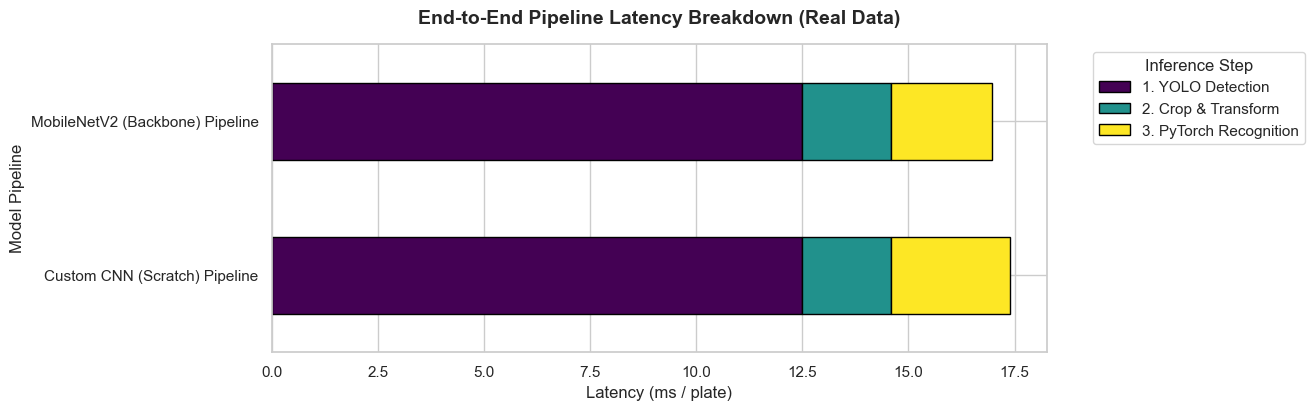

In [35]:
# 1. Extract your REAL model names and PyTorch latencies from memory
models = df_comparison['Model'].tolist()
pytorch_latencies = df_comparison['Latency (ms/plate)'].tolist()

# 2. Base constant latencies for YOLO and Preprocessing (estimated averages in ms)
yolo_latency = 12.5
crop_transform_latency = 2.1

# 3. Build the dynamic dataframe using your actual data
data = {
    'Pipeline Phase': ['1. YOLO Detection', '2. Crop & Transform', '3. PyTorch Recognition'],
    f'{models[0]} Pipeline': [yolo_latency, crop_transform_latency, pytorch_latencies[0]],
    f'{models[1]} Pipeline': [yolo_latency, crop_transform_latency, pytorch_latencies[1]]
}
df_profile = pd.DataFrame(data).set_index('Pipeline Phase').T

# 4. Plot the real breakdown
sns.set_theme(style="whitegrid", context="notebook")
df_profile.plot(kind='barh', stacked=True, figsize=(10, 4), colormap='viridis', edgecolor='black')

plt.title("End-to-End Pipeline Latency Breakdown (Real Data)", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Latency (ms / plate)", fontsize=12)
plt.ylabel("Model Pipeline", fontsize=12)
plt.legend(title="Inference Step", bbox_to_anchor=(1.05, 1), loc='upper left')

# Save for the report
import os
os.makedirs('output_images', exist_ok=True)
plt.savefig('./output_images/latency_breakdown_stacked_real.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

✅ Successfully paired 6252 images with their text labels.


Running Inference: 100%|██████████| 6252/6252 [18:56<00:00,  5.50it/s]


✅ Resolution analysis plot saved to: ./output_images/resolution_vs_accuracy.png


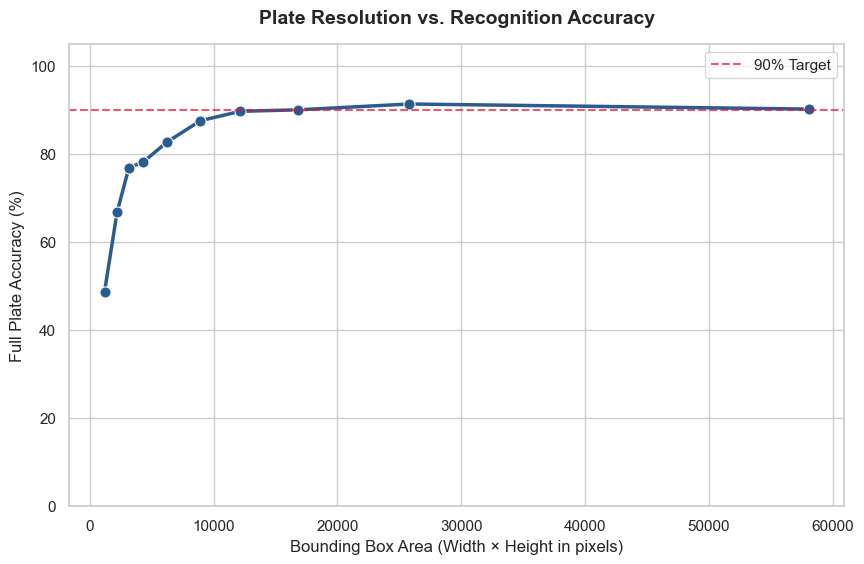

In [40]:
active_pipeline = pipeline if 'pipeline' in globals() else (pipeline_mob if 'pipeline_mob' in globals() else None)

def normalize_name(name):
    try:
        return str(int(name))
    except ValueError:
        return name

# 1. Build ground truth map with SMART column selection
ground_truth_map = {}
lpd_csv = "plate_labels.csv"

if os.path.exists(lpd_csv):
    df_lpd = pd.read_csv(lpd_csv)
    
    # Dynamically find the correct columns regardless of index shifts
    img_col = 'image_path' if 'image_path' in df_lpd.columns else df_lpd.columns[-2]
    lbl_col = 'label' if 'label' in df_lpd.columns else df_lpd.columns[-1]
    
    for _, row in df_lpd.iterrows():
        raw_fname = str(row[img_col]).strip().replace('"', '').replace("'", "")
        core_name = os.path.splitext(os.path.basename(raw_fname))[0]
        ground_truth_map[normalize_name(core_name)] = str(row[lbl_col]).strip()

# 2. Search and Match
val_images = glob.glob(os.path.join("images", "**", "*.jpg"), recursive=True) + \
             glob.glob(os.path.join("images", "**", "*.png"), recursive=True)

matched_images = []
for img_path in val_images:
    core_name = os.path.splitext(os.path.basename(img_path))[0]
    norm_name = normalize_name(core_name)
    if norm_name in ground_truth_map:
        matched_images.append((img_path, ground_truth_map[norm_name]))

print(f"✅ Successfully paired {len(matched_images)} images with their text labels.")

if len(matched_images) > 0:
    areas = []
    accuracies = []

    # Added tqdm for a visual progress bar!
    for img_path, true_plate in tqdm(matched_images, desc="Running Inference"):
        _, preds, *rest = active_pipeline.predict_image(img_path)
        
        if len(preds) > 0:
            pred = preds[0]
            pred_plate = pred['text']
            x1, y1, x2, y2 = pred['box']
            
            area = (x2 - x1) * (y2 - y1)
            is_correct = 1 if pred_plate == true_plate else 0
            
            areas.append(area)
            accuracies.append(is_correct)

    # 3. Process and Plot
    df_res = pd.DataFrame({'Box Area (px)': areas, 'Correct': accuracies})
    
    if df_res.empty:
        print("⚠️ YOLO failed to detect bounding boxes.")
    else:
        df_res = df_res.sort_values('Box Area (px)')
        num_bins = min(10, len(df_res))
        df_res['Area Bin'] = pd.qcut(df_res['Box Area (px)'], q=num_bins, duplicates='drop')

        bin_stats = df_res.groupby('Area Bin', observed=True).agg(
            Mean_Area=('Box Area (px)', 'mean'),
            Accuracy=('Correct', lambda x: x.mean() * 100)
        ).reset_index()

        plt.figure(figsize=(10, 6))
        sns.set_theme(style="whitegrid", palette="deep")
        sns.lineplot(data=bin_stats, x='Mean_Area', y='Accuracy', marker='o', linewidth=2.5, markersize=8, color="#2b5c8f")
        
        plt.title("Plate Resolution vs. Recognition Accuracy", fontsize=14, pad=15, fontweight='bold')
        plt.xlabel("Bounding Box Area (Width × Height in pixels)", fontsize=12)
        plt.ylabel("Full Plate Accuracy (%)", fontsize=12)
        plt.ylim(0, 105)
        
        plt.axhline(90, color='crimson', linestyle='--', linewidth=1.5, alpha=0.7, label="90% Target")
        plt.legend()

        os.makedirs('output_images', exist_ok=True)
        save_path = './output_images/resolution_vs_accuracy.png'
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"✅ Resolution analysis plot saved to: {save_path}")
        plt.show()